# Homework #3 - Sistemi Informativi Evoluti e Big Data (2025-2026)
## Artificial Intelligence Publication Trends - Neo4j
Camossi Filippo (734170)

Questo notebook implementa l'analisi completa del dataset [Artificial Intelligence Publication Trends](https://arxiv.org) utilizzando Neo4j.

## Setup - Installazione delle librerie necessarie

In [1]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

## 1. Caricamento dei Dati

### 1.1 Connessione al Database e Funzioni di Supporto

In [2]:
# Connessione a Neo4j
uri = "bolt://localhost:7687"
username = "neo4j"
password = "neo4j_sirio"

# Inizializza il driver
driver = GraphDatabase.driver(uri,auth=(username,password))

def run_query(query, parameters=None):
    """Funzione per eseguire query Cypher"""
    with driver.session() as session:
        result = session.run(query, parameters)
        return [record.data() for record in result]

def clear_db():
    """Cancella tutto il database"""
    query = "MATCH (n) DETACH DELETE n"
    run_query(query)
    print("Database pulito")

# Verifica connessione
try:
    driver.verify_connectivity()
    print("Connessione a Neo4j riuscita")
except Exception as e:
    print(f"Errore di connessione: {e}")

# clear_db()

Connessione a Neo4j riuscita


### 1.2 Caricamento e Pulizia dei Dataset

Carichiamo i tre file CSV:
- `arxiv_papers.csv`: informazioni sugli articoli
- `papers_with_topics.csv`: associazione paper-topic con probabilità
- `topic_definitions.csv`: definizioni dei topic

In [5]:
# Caricamento CSV
df_papers = pd.read_csv('Dataset/arxiv_papers.csv')
df_topics = pd.read_csv('Dataset/papers_with_topics.csv')
df_defs = pd.read_csv('Dataset/topic_definitions.csv')

# Conversione data (solo data, non il timestamp)
df_papers['date'] = pd.to_datetime(df_papers['published']).dt.strftime('%Y-%m-%d')

# Conversione stringa "['Autore 1', 'Autore 2']" in una lista
df_papers['authors_list'] = df_papers['authors'].apply(ast.literal_eval)

# Conversione stringhe in liste/numeri
df_topics['top_topics_list'] = df_topics['top_topics'].apply(ast.literal_eval)
df_topics['top_probs_list'] = df_topics['top_probabilities'].apply(ast.literal_eval)

print(f"Papers: {len(df_papers)} righe")
print(f"Papers with topics: {len(df_topics)} righe")
print(f"Topic definitions: {len(df_defs)} righe")

Papers: 8000 righe
Papers with topics: 8000 righe
Topic definitions: 132 righe


### 1.3 Popolamento del Grafo

- nodo Paper per ogni articolo
- nodo Author per ogni autore
- nodo Topic estratto da abstract dei paper
- relazioni :AUTHORED tra Paper e Author
- relazioni :ON_TOPIC tra Paper e Topic con proprietà di probabilità
- relazioni :COAUTHORED_WITH tra Author che hanno lavorato agli stessi paper

In [ ]:
def ingest_data_batch(query, batch_data):
    """Esegue una query di scrittura passando un batch di dati"""
    run_query(query, {'batch': batch_data})

batch_size = 1000

# Creazione Nodi PAPER
# Proprietà: title, abstract, date (YYYY-MM-DD), url
print("Creazione Nodi Paper...")
query_papers = """
UNWIND $batch AS row
MERGE (p:Paper {url: row.url})
SET p.title = row.title,
    p.abstract = row.abstract,
    p.date = date(row.date)  // Conversione stringa -> Oggetto Date
"""
records_papers = df_papers.to_dict('records')
for i in range(0, len(records_papers), batch_size):
    ingest_data_batch(query_papers, records_papers[i:i+batch_size])
print(f"Aggiunti {len(records_papers)} articoli\n")


# Creazione Nodi AUTHOR
# Proprietà: name
print("Creazione Nodi Author...")
query_authors = """
UNWIND $batch AS row
UNWIND row.authors_list AS author_name
MERGE (a:Author {name: trim(author_name)})
"""
# Riusa records_papers perché contiene la lista autori
for i in range(0, len(records_papers), batch_size):
    ingest_data_batch(query_authors, records_papers[i:i+batch_size])
print("Completato\n")


# Creazione Nodi TOPIC
# Estratti dagli abstract (topic_definitions.csv)
print("Creazione Nodi Topic...")
query_topics = """
UNWIND $batch AS row
MERGE (t:Topic {id: row.Topic})
SET t.name = row.Name, 
    t.keywords = row.Representation
"""
ingest_data_batch(query_topics, df_defs.to_dict('records'))
print("Completato\n")

# Relazione :AUTHORED (Paper <-> Author)
print("Creazione relazione :AUTHORED...")
query_rel_authored = """
UNWIND $batch AS row
MATCH (p:Paper {url: row.url})
UNWIND row.authors_list AS author_name
MATCH (a:Author {name: trim(author_name)})
MERGE (a)-[:AUTHORED]->(p)
"""
for i in range(0, len(records_papers), batch_size):
    ingest_data_batch(query_rel_authored, records_papers[i:i+batch_size])
print("Completato\n")

# Relazione :ON_TOPIC (Paper <-> Topic) con probabilità
print("Creazione relazione :ON_TOPIC...")
query_rel_ontopic = """
UNWIND $batch AS row
MATCH (p:Paper {url: row.url})
// Iteriamo sugli indici della lista topics (0, 1, 2)
FOREACH (i IN range(0, size(row.top_topics_list)-1) | 
    MERGE (t:Topic {id: row.top_topics_list[i]})
    MERGE (p)-[r:ON_TOPIC]->(t)
    SET r.probability = row.top_probs_list[i]
)
"""
records_topics = df_topics.to_dict('records')
for i in range(0, len(records_topics), batch_size):
    ingest_data_batch(query_rel_ontopic, records_topics[i:i+batch_size])
print("Completato\n")

# Relazione :COAUTHORED_WITH (Author <-> Author)
print("Creazione relazione :COAUTHORED_WITH (Batch)...")
query_coauthor = """
MATCH (a1:Author)
CALL (a1) {
    MATCH (a1)-[:AUTHORED]->(p:Paper)<-[:AUTHORED]-(a2:Author)
    WHERE elementId(a1) < elementId(a2)
    WITH a1, a2, count(p) as common
    MERGE (a1)-[r:COAUTHORED_WITH]-(a2)
    SET r.count = common
} IN TRANSACTIONS OF 100 ROWS
"""
run_query(query_coauthor)

print("\nTutti i nodi e relazioni sono stati caricati correttamente")

Creazione Nodi Paper...
Aggiunti 8000 articoli

Creazione Nodi Author...
Completato

Creazione Nodi Topic...
Completato

Creazione relazione :AUTHORED...
Completato

Creazione relazione :ON_TOPIC...
Completato

Creazione relazione :COAUTHORED_WITH (Batch)...

Tutti i nodi e relazioni sono stati caricati correttamente


### 1.4 Creazione delle relazioni SIMILAR_TOPIC

Calcola la similarità di Jaccard pesata (similarità di Ruzicka) tra paper basata sui topic condivisi:

$$sim_{T}(p,q) = \frac{\sum_{i \in U_T} \min(p_i, q_i)}{\sum_{i \in U_T} \max(p_i, q_i)}$$

dove $p_i$ e $q_i$ sono le probabilità del topic $i$ per i paper $p$ e $q$.

In [ ]:
def calculate_ruzicka_similarity():
    print("Avvio calcolo Similarità Ruzicka...")

    # 1: Pre-calcolo dei pesi totali per ogni Paper
    # La Jaccard richiede il denominatore (Unione).
    # Matematicamente: Union(A,B) = Sum(A) + Sum(B) - Intersection(A,B)
    # Calcola Sum(A) per ogni paper e salvata come proprietà 'topic_weight'.
    query_weights = """
    MATCH (p:Paper)-[r:ON_TOPIC]->()
    WITH p, sum(r.probability) AS total_weight
    SET p.topic_weight = total_weight
    """
    print("Calcolo dei pesi totali dei topic per paper...")
    run_query(query_weights)

    # 2: Calcolo Similarità e Creazione Relazioni
    # Confronta coppie di paper che condividono almeno un topic.
    query_similarity = """
    MATCH (p1:Paper)-[r1:ON_TOPIC]->(t:Topic)<-[r2:ON_TOPIC]-(p2:Paper)
    WHERE elementId(p1) < elementId(p2)
    
    // 1. Calcolo Numeratore: Somma dei Minimi (Intersezione)
    WITH p1, p2, sum(
        CASE WHEN r1.probability < r2.probability THEN r1.probability 
        ELSE r2.probability END
    ) AS intersection_sum
    
    // 2. Calcolo Denominatore: Somma dei Massimi (Unione)
    WITH p1, p2, intersection_sum, 
        (p1.topic_weight + p2.topic_weight - intersection_sum) AS union_sum
    
    // 3. Calcolo Score e Filtro
    WHERE union_sum > 0
    WITH p1, p2, intersection_sum / union_sum AS sim_score
    WHERE sim_score > 0.15  // SOGLIA: Salviamo solo se > 0.15 per non riempire il DB di archi deboli
    
    // 4. Scrittura Relazione
    MERGE (p1)-[s:SIMILAR_TOPIC]-(p2)
    SET s.score = sim_score
    """
    
    print("Creazione relazioni :SIMILAR_TOPIC...")

    run_query(query_similarity)
    print("Calcolo similarità completato")

# Esecuzione
calculate_ruzicka_similarity()

Avvio calcolo Similarità Ruzicka...
Calcolo dei pesi totali dei topic per paper...
Creazione relazioni :SIMILAR_TOPIC...
Calcolo similarità completato



## 2. Interrogazioni Analitiche

### Query 1: Schema del Database

>Visualizzare lo “schema” del database (tipi di nodi e di relazioni tra i nodi) tramite Neo4j Desktop.

```cypher
CALL db.schema.visualization()
```

<img src="Images/Query1.png">

### Query 2: Top 5 autori per numero di articoli

>Estrarre i primi 5 autori come numero di articoli di cui sono autori o co-autori.

            author  papers_count
0         Wei Wang            19
1          Yang Li            19
2         Yang Liu            18
3         Xin Wang            15
4  H. Vincent Poor            13


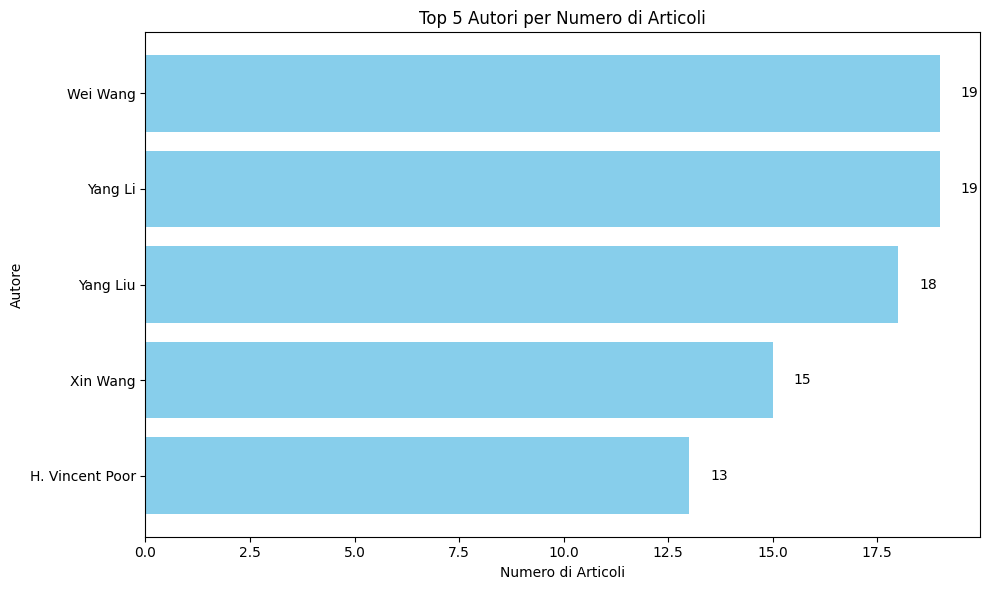

In [8]:
query = """
MATCH (a:Author)-[:AUTHORED]->(p:Paper)
RETURN a.name AS author, COUNT(p) AS papers_count
ORDER BY papers_count DESC
LIMIT 5
"""

results = run_query(query)

df_authors = pd.DataFrame([dict(record) for record in results])
print(df_authors.to_string())

# Grafico
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(df_authors['author'], df_authors['papers_count'], color='skyblue')
ax.set_xlabel('Numero di Articoli')
ax.set_ylabel('Autore')
ax.set_title('Top 5 Autori per Numero di Articoli')
ax.invert_yaxis()  # Mostra il primo in alto

for bar, count in zip(bars, df_authors['papers_count']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, 
            str(count), va='center', fontsize=10)

plt.tight_layout()
plt.show()

### Query 3: Andamento temporale delle pubblicazioni

>Estrarre l’andamento temporale del numero di paper pubblicati nel corso degli anni e visualizzare il risultato in un grafico a barre in Python.

   year  papers_count
0  2021          8000


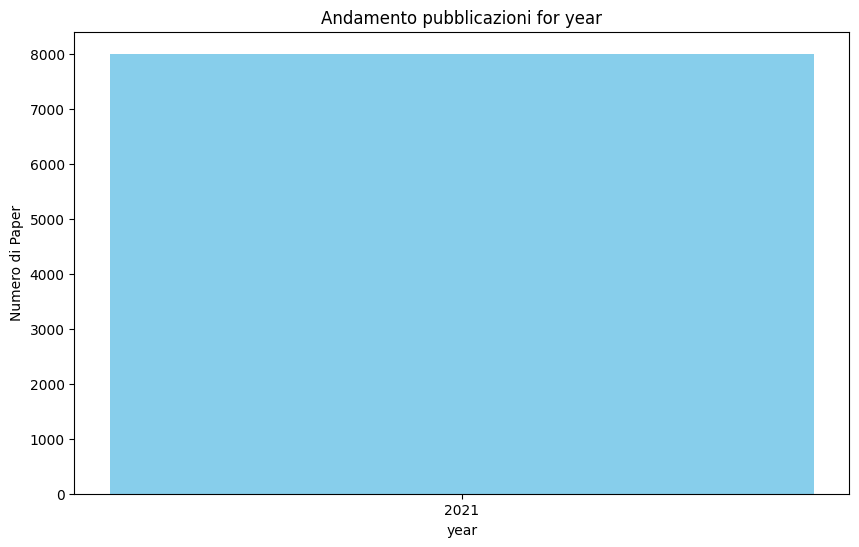

In [9]:
# Tutti i paper sono stati pubblicati nel 2021, aggiunta la possibilità di filtrare per mese per un grafico più significativo
soglia_tmp = 'year'
# soglia_tmp = 'month'

query = f"""
MATCH (p:Paper)
RETURN p.date.{soglia_tmp} AS {soglia_tmp}, COUNT(p) AS papers_count
ORDER BY {soglia_tmp}
"""

results = run_query(query)
temporal_df = pd.DataFrame(results)

print(temporal_df.to_string())

# Grafico a barre
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(temporal_df[soglia_tmp].astype(str), temporal_df['papers_count'], color='skyblue')
plt.title(f'Andamento pubblicazioni for {soglia_tmp}')
plt.xlabel(soglia_tmp)
plt.ylabel('Numero di Paper')
plt.show()

### Query 4: Percorso più breve tra due autori

>Trovare il percorso più breve tra due autori (a scelta dello studente) e visualizzarlo come sottografo tramite Neo4j Desktop.

```cypher
MATCH (a1:Author {name: 'Xin Wang'}), (a2:Author {name: 'Yang Li'})
MATCH p = shortestPath((a1)-[:COAUTHORED_WITH*]-(a2)) 
RETURN p
```

<img src="Images/Query4.png">

### Query 5: Similarità tra autori

>Calcolare la similarità tra tutte le possibili coppie di autori a1 e a2, applicando la seguente formula (dove P1 e P2 rappresentano l’insieme degli articoli associati ai due autori, rispettivamente, e |.| rappresenta la cardinalità di un insieme):

$$Sim(a_1, a_2) = \frac{1}{|P_1| \cdot |P_2|} \sum_{p_i \in P_1} \sum_{p_j \in P_2} sim_{T}(p_i, p_j)$$

Il calcolo della similarità su tutte le possibili coppie di autori dell'intero dataset (N≈37k) richiederebbe tempi di elaborazione troppo lunghi. Pertanto, l'analisi è stata applicata al sottoinsieme significativo del 10% degli autori

In [3]:
query = """
MATCH (a:Author)-[:AUTHORED]->(p:Paper)
WITH a, count(p) as cnt
ORDER BY cnt DESC
LIMIT 3760 // 10% autori
// Raccogliamo sia l'autore che il suo conteggio in una lista di oggetti
WITH collect({node: a, count: cnt}) as top_data

// Generazione coppie
UNWIND top_data as d1
UNWIND top_data as d2

WITH d1, d2
WHERE elementId(d1.node) < elementId(d2.node) // Evita duplicati
WITH d1.node as a1, d1.count as len1, d2.node as a2, d2.count as len2

// Naviga il grafo e cerca relazioni di similarità tra i loro paper (Variable Length Path)
// *0 (Distanza Zero): p1=p2
// *1 (Distanza Uno): relazione :SIMILAR_TOPIC tra p1 e p2
MATCH (a1)-[:AUTHORED]->(p1:Paper)-[s:SIMILAR_TOPIC*0..1]-(p2:Paper)<-[:AUTHORED]-(a2)

// Calcolo numeratore
WITH a1, a2, len1, len2,
    sum(
        CASE 
        WHEN p1 = p2 THEN 1.0           // Stesso paper = 1
        ELSE coalesce(last(s).score, 0) // Paper simile = score
        END
    ) as total_sim

// Formula Finale
WITH a1, a2, (total_sim / toFloat(len1 * len2)) as final_score
WHERE final_score > 0

RETURN a1.name AS Autore1, a2.name AS Autore2, final_score AS Similarita
ORDER BY final_score DESC
"""

# Esegui la query
similarity_results = run_query(query)
for record in similarity_results[:20]:
    print(f"{record['Autore1']} <-> {record['Autore2']}: Similarità = {record['Similarita']:.4f}")

Sarwan Ali <-> Murray Patterson: Similarità = 1.0000
Sarwan Ali <-> Guo-Wei Wei: Similarità = 1.0000
Murray Patterson <-> Guo-Wei Wei: Similarità = 1.0000
Julien Berger <-> Madina Abdykarim: Similarità = 1.0000
Weidong Mei <-> Changsheng You: Similarità = 1.0000
Weidong Mei <-> Vahid Jamali: Similarità = 1.0000
Weidong Mei <-> Beixiong Zheng: Similarità = 1.0000
Weidong Mei <-> Sergei Tretyakov: Similarità = 1.0000
Andrea Bisoffi <-> D. Nešić: Similarità = 1.0000
Andrea Bisoffi <-> R. Postoyan: Similarità = 1.0000
Andrea Bisoffi <-> W. P. M. H. Heemels: Similarità = 1.0000
Andrea Bisoffi <-> Tom Oomen: Similarità = 1.0000
Tengfei Liang <-> Yidong Li: Similarità = 1.0000
Tengfei Liang <-> Yi Jin: Similarità = 1.0000
Tengfei Liang <-> Wu Liu: Similarità = 1.0000
Yi Jin <-> Yidong Li: Similarità = 1.0000
Yi Jin <-> Wu Liu: Similarità = 1.0000
Sihan Yuan <-> Daniel J. Eisenstein: Similarità = 1.0000
Wu Liu <-> Yidong Li: Similarità = 1.0000
Jingyuan Yang <-> Xiumei Wang: Similarità = 1.000

### Query 6: Grafo di co-authorship dei Top 20 autori più prolifici

>Visualizzare come grafo la rete di co-authorship filtrata ai primi 20 autori più prolifici.

```cypher
MATCH (a:Author) 
WITH a, count {(a)-[:AUTHORED]->()} as cnt 
ORDER BY cnt DESC 
LIMIT 20
WITH collect(a) as tops MATCH (a1)-[r:COAUTHORED_WITH]-(a2)
WHERE a1 IN tops AND a2 IN tops 
RETURN a1, r, a2
```

<img src="Images/Query6.png">

### Chiusura Connessione al database Neo4j.

In [ ]:
# Chiusura della connessione al database
driver.close()
print("Connessione a Neo4j chiusa correttamente")